# Annotations

DS 2023 | Communicating with Data

## Overview

A plot shows data.

An **annotation** tells the reader what to notice in it.

In Matplotlib, the word *annotation* usually means one method, `ax.annotate()`, which places text and an arrow.

In this notebook we take a wider view.

We will call any mark that guides the reader's interpretation, without itself encoding an observation, an annotation.

By that definition, all of these are annotations:

- **text**: a label placed anywhere on the plot,
- **callouts**: text with an arrow pointing to a feature,
- **reference lines**: a threshold, an average, a target, a date,
- **regions**: a shaded band for a period, a range, or a gap between two series,
- **labels on marks**: the value printed on each bar,
- **shapes**: a box or ellipse drawn around a cluster,
- **emphasis**: one series in color while the others are gray,
- **figure-level marks**: a title over several panels, panel letters, lines that connect one panel to another.

Titles, axis labels, and legends belong on this list too.

We have used them since the first plotting notebook, so we will treat them briefly.

The question this notebook keeps asking is: **what should the reader see first, and how do we point to it?**

## Use Cases

- **Marking an event**: a recession, a policy change, a pandemic year on a time series.
- **Labeling an extreme**: the busiest month, the largest outlier, the record high.
- **Showing a threshold**: break-even, a passing grade, a legal limit, the mean.
- **Comparing to a range**: one country against the band formed by all the others.
- **Reading exact values**: counts printed on bars when readers need the numbers.
- **Guiding a multi-panel figure**: panel letters, a shared title, a zoom from an overview to a detail.

## Set Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
healthexp = sns.load_dataset('healthexp')
flights = sns.load_dataset('flights')
penguins = sns.load_dataset('penguins').dropna()
mpg = sns.load_dataset('mpg')

We will use two wide tables throughout, shaped as in earlier notebooks.

Each has years in the index and one column per series.

In [4]:
life = healthexp.pivot(index='Year', columns='Country', values='Life_Expectancy')
passengers = flights.pivot(index='year', columns='month', values='passengers')
annual = passengers.sum(axis=1)

## Where Annotations Live: Coordinate Systems

Every annotation must be placed somewhere.

So before we add any, we need to know how Matplotlib describes *where*.

There are three coordinate systems we will use.

| System | Runs from | Use it when the annotation belongs to... |
|---|---|---|
| **Data** (the default) | the axis values, such as years and passengers | a data point or value |
| **Axes fraction** | (0, 0) at the bottom left of the axes to (1, 1) at the top right | a position in the plot box, such as a corner |
| **Figure fraction** | (0, 0) to (1, 1) across the whole figure | the figure as a whole, across panels |

We met figure fractions in *Subplots and Mosaics*, when we placed axes by hand with `fig.add_axes()`.

Let's put one label in each system.

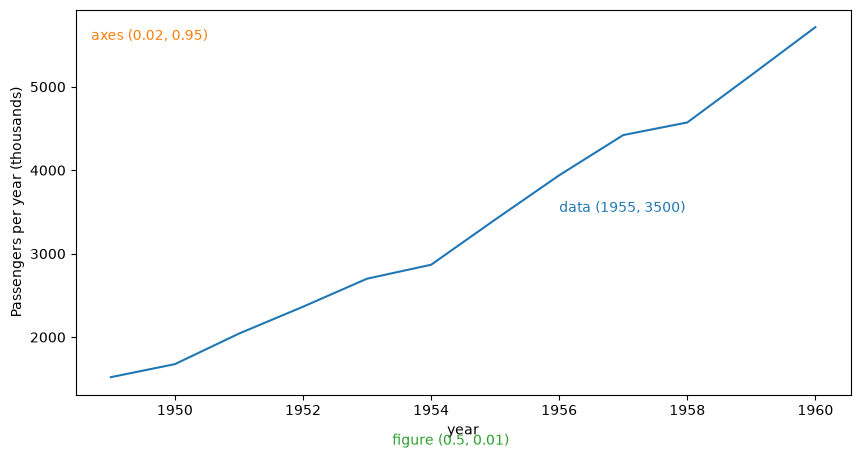

In [52]:
fig, ax = plt.subplots(figsize=(10, 5))

annual.plot(ax=ax, color='tab:blue')

ax.text(1956, 3500, 'data (1955, 3500)', color='tab:blue')
ax.text(0.02, 0.95, 'axes (0.02, 0.95)', transform=ax.transAxes, color='tab:orange', va='top')
fig.text(0.5, 0.01, 'figure (0.5, 0.01)', ha='center', color='tab:green')

ax.set_ylabel('Passengers per year (thousands)')
plt.show()

The blue label is tied to the data.

If the axis limits change, it moves with the line.

The orange label is tied to the axes box, through `transform=ax.transAxes`.

It stays in the top left corner whatever the data are.

The green label is tied to the figure, and sits below the axes entirely.

```{tip}
Use data coordinates for anything that points at the data.
Use axes or figure coordinates for anything that labels the plot itself, such as a note, a source line, or a panel letter.
```

## Text

`ax.text(x, y, s)` writes the string `s` at the point (x, y).

It is the simplest annotation, and every other text annotation is built on it.

Its most useful parameters control alignment and appearance.

| Parameter | Does |
|---|---|
| `ha` | horizontal alignment of the text *relative to the point*: `'left'`, `'center'`, `'right'` |
| `va` | vertical alignment: `'bottom'`, `'center'`, `'top'`, `'baseline'` |
| `fontsize`, `fontweight`, `color` | appearance |
| `rotation` | angle in degrees |
| `bbox` | a dictionary describing a box behind the text |
| `transform` | the coordinate system, such as `ax.transAxes` |

Alignment confuses almost everyone at first.

`ha='left'` does not move the text to the left.

It puts the *left edge* of the text at the point.

Let's see all three settings at once, with a dot marking the point.

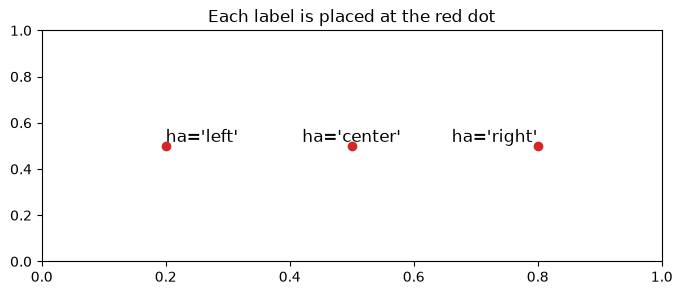

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))

for x, ha in zip([0.2, 0.5, 0.8], ['left', 'center', 'right']):
    ax.plot(x, 0.5, 'o', color='tab:red')
    ax.text(x, 0.5, f"ha='{ha}'", ha=ha, va='bottom', fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title('Each label is placed at the red dot')
plt.show()

### Direct labeling

A common use of `text()` is to label lines directly, at their ends, instead of with a legend.

The reader no longer has to match colors between the legend and the plot.

Here is life expectancy, with each country labeled at its last year.

In [41]:
life.head()

Country,Canada,France,Germany,Great Britain,Japan,USA
Year,,,,,,
1970,NaN,72.2,70.6,71.9,72.0,70.9
1971,72.8,NaN,70.8,71.9,72.9,71.2
1972,NaN,NaN,71.0,NaN,73.2,71.2
1973,NaN,NaN,71.3,NaN,73.4,71.4
1974,NaN,NaN,71.5,NaN,73.7,72.0


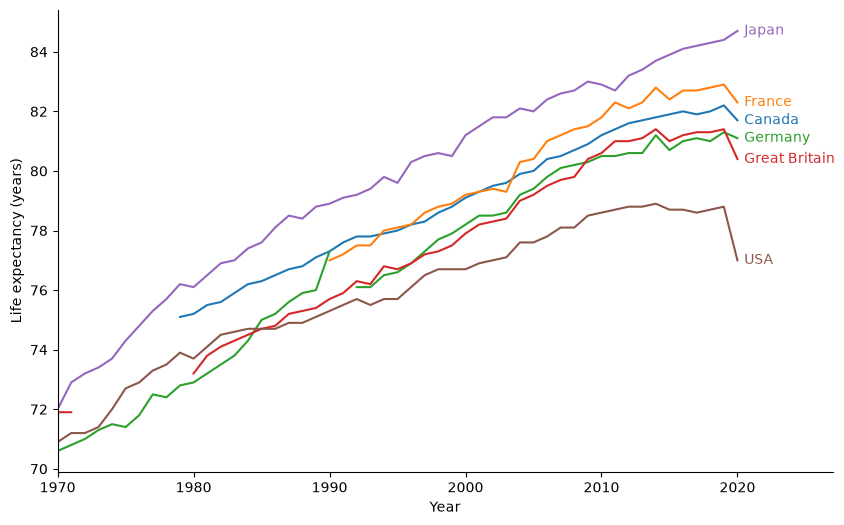

In [42]:
fig, ax = plt.subplots(figsize=(10, 6))

life.plot(ax=ax, legend=False)

for line in ax.lines:
    color = line.get_color()
    label = line.get_label()
    x = line.get_data()[0][-1]
    y = line.get_data()[1][-1]
    ax.text(x + .5, y, label, color=color, va='center')

ax.set_xlim(1970, 2027)
ax.set_ylabel('Life expectancy (years)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The `.plot()` method returns a list of the lines it drew.

The comma in `line, =` unpacks the single line, so that we can ask for its color with `get_color()` and give the label the same color.

Notice that Canada, France, and Germany crowd together near 81 and 82.

Direct labels work best when the line ends are well separated.

When they are not, we nudge the labels by hand or fall back on a legend.

### Text in a box

The `bbox` parameter draws a box behind the text.

It is useful for notes that sit on top of data, where the box keeps the text readable.

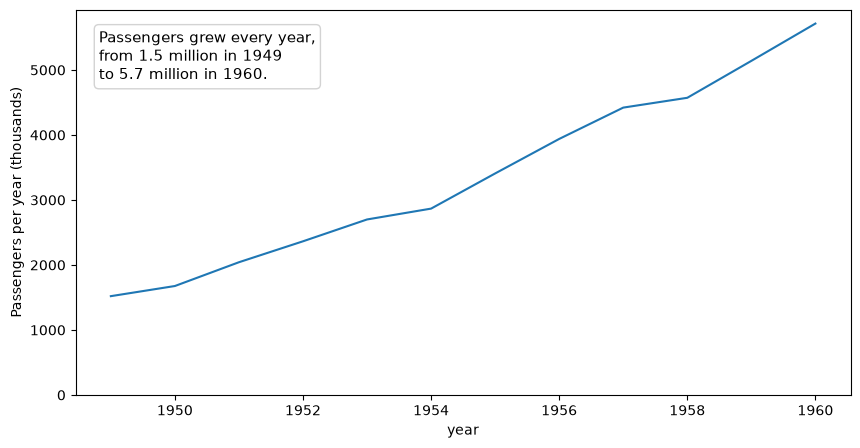

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))

annual.plot(ax=ax, color='tab:blue')

ax.text(
    0.03, 
    0.95,
    'Passengers grew every year,\nfrom 1.5 million in 1949\nto 5.7 million in 1960.',
    transform=ax.transAxes, 
    va='top', 
    fontsize=11,
    bbox=dict(boxstyle='round', facecolor='white', edgecolor='lightgray'))

ax.set_ylim(0)
ax.set_ylabel('Passengers per year (thousands)')
plt.show()

## Callouts with `annotate()`

`ax.annotate()` is `text()` with an arrow.

It takes two positions:

- `xy`, the point being annotated, where the arrow ends,
- `xytext`, where the text goes, where the arrow starts.

The arrow is drawn only if we pass `arrowprops`, a dictionary of arrow properties.

Let's point to the busiest month in the `flights` data.

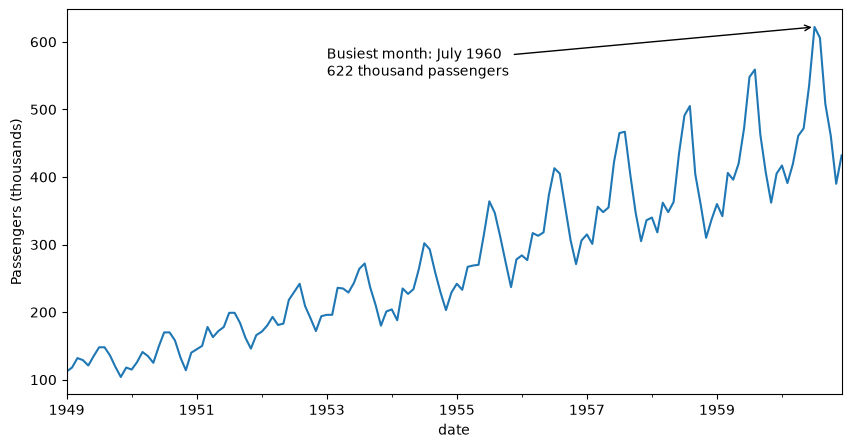

In [45]:
monthly = flights.assign(date=pd.to_datetime(flights.year.astype(str) + '-' + flights.month.astype(str), format='%Y-%b'))
monthly = monthly.set_index('date').passengers

peak_date = monthly.idxmax()
peak_value = monthly.max()

fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(ax=ax, color='tab:blue')

ax.annotate(f'Busiest month: {peak_date:%B %Y}\n{peak_value} thousand passengers',
            xy=(peak_date, peak_value),
            xytext=(pd.Timestamp('1953-01-01'), 550),
            arrowprops=dict(arrowstyle='->', color='black'))

ax.set_ylabel('Passengers (thousands)')
plt.show()

Notice that we did not type the date or the number into the label.

We computed them with `idxmax()` and `max()`, so the annotation stays correct if the data change.

```{important}
Compute annotation positions and values from the data whenever you can.

A hard-coded arrow points to the right place only for the data it was written for.
```

### Offsets instead of positions

Choosing `xytext` in data coordinates can be awkward, because we must think in dates and passengers to place a label.

Often it is easier to say *how far* the text should be from the point, in screen units.

`textcoords='offset points'` does this.

A **point** is 1/72 of an inch, the unit of font sizes.

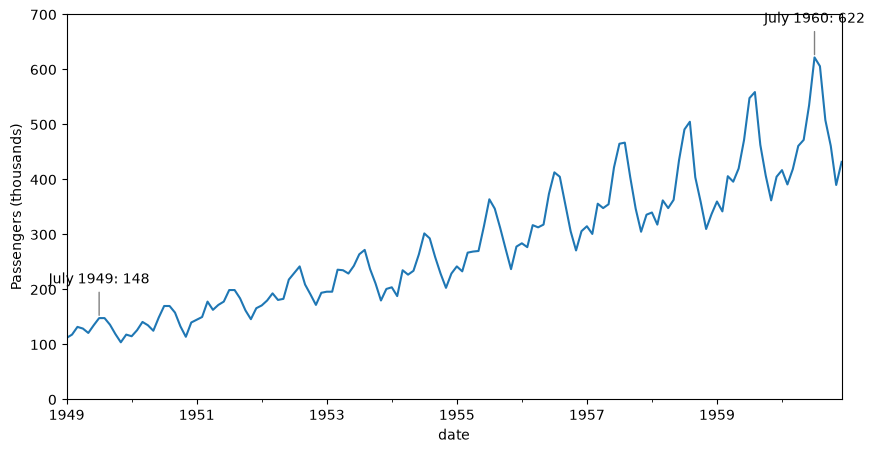

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(ax=ax, color='tab:blue')

for year in [1949, 1960]:
    july = pd.Timestamp(f'{year}-07-01')
    ax.annotate(f'July {year}: {monthly[july]}',
                xy=(july, monthly[july]),
                xytext=(0, 25), textcoords='offset points',
                ha='center',
                arrowprops=dict(arrowstyle='-', color='gray'))

ax.set_ylim(0, 700)
ax.set_ylabel('Passengers (thousands)')
plt.show()

Each label sits 25 points directly above its point, whatever the axis scales are.

The July peak more than quadrupled in twelve years.

### Arrow styles

`arrowprops` accepts many options.

The two we use most are `arrowstyle` and `connectionstyle`, which bends the arrow.

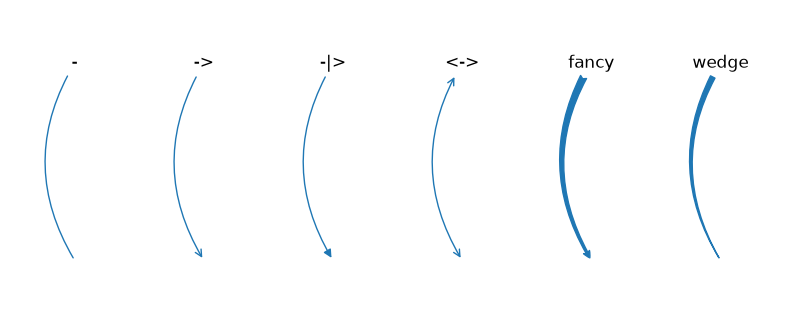

In [47]:
styles = ['-', '->', '-|>', '<->', 'fancy', 'wedge']

fig, ax = plt.subplots(figsize=(10, 4))

for i, style in enumerate(styles):
    ax.annotate(style, xy=(i, 0), xytext=(i, 1),
                ha='center', fontsize=12,
                arrowprops=dict(arrowstyle=style, color='tab:blue',
                                connectionstyle='arc3,rad=0.3'))

ax.set_xlim(-0.5, len(styles) - 0.5)
ax.set_ylim(-0.3, 1.3)
ax.set_axis_off()
plt.show()

`'arc3,rad=0.3'` curves each arrow; `rad=0` is straight.

A gentle curve can route an arrow around data that a straight arrow would cross.

## Reference Lines

A reference line marks a value that is not in the data but helps us read it: an average, a target, a date.

| Method | Draws |
|---|---|
| `ax.axhline(y)` | a horizontal line across the whole axes |
| `ax.axvline(x)` | a vertical line across the whole axes |
| `ax.hlines(y, xmin, xmax)` | horizontal segments with set ends, one or many |
| `ax.vlines(x, ymin, ymax)` | vertical segments with set ends, one or many |
| `ax.axline(xy1, xy2)` or `ax.axline(xy1, slope=m)` | an infinite line through a point at any angle |

Lines rarely speak for themselves, so we usually pair them with `text()`.

Here are penguin body masses, with the overall mean as a reference.

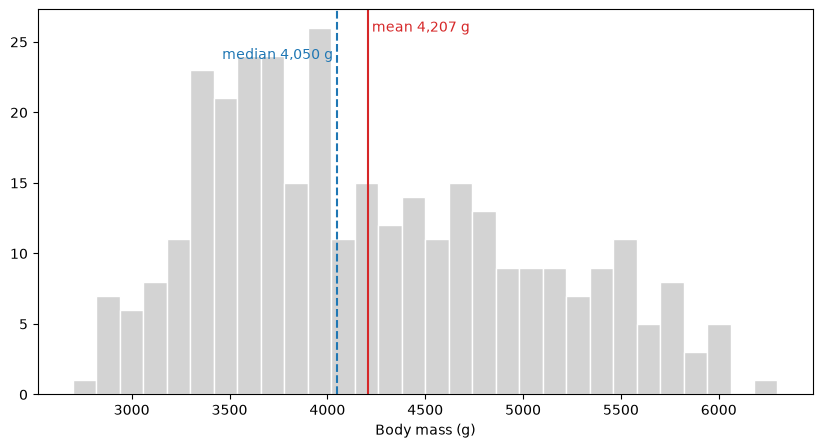

In [48]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(penguins.body_mass_g, bins=30, color='lightgray', edgecolor='white')

mean = penguins.body_mass_g.mean()
median = penguins.body_mass_g.median()

ax.axvline(mean, color='tab:red')
ax.text(mean, 0.97, f' mean {mean:,.0f} g', color='tab:red',
        transform=ax.get_xaxis_transform(), va='top')

ax.axvline(median, color='tab:blue', linestyle='--')
ax.text(median, 0.90, f'median {median:,.0f} g ', color='tab:blue',
        transform=ax.get_xaxis_transform(), va='top', ha='right')

ax.set_xlabel('Body mass (g)')
plt.show()

Look at the `transform` in the `text()` calls.

`ax.get_xaxis_transform()` is a **blended** coordinate system: x is in data coordinates, and y is in axes fraction.

So each label sits at its line's x value, near the top of the plot, whatever the heights of the bars.

The mean is to the right of the median.

That is what we expect from a right-skewed distribution, as we saw in the *Statistics Primer*.

### A diagonal reference

`axline()` draws lines at any angle.

In a scatter plot of two measurements in the same units, the line y = x is often the most useful reference.

Here is Japan's life expectancy against the USA's, one point per year.

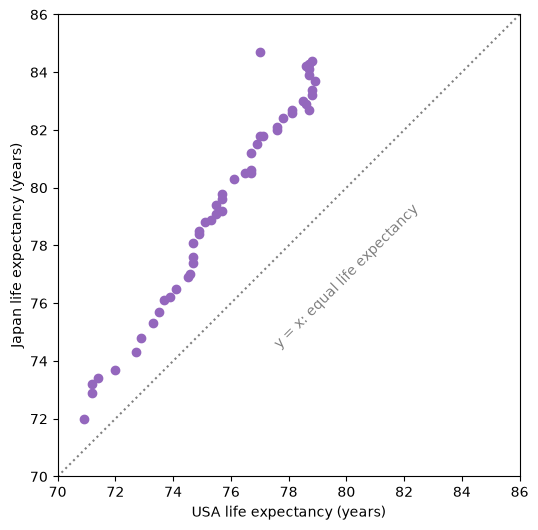

In [50]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(life.USA, life.Japan, color='tab:purple')
ax.axline((75, 75), slope=1, color='gray', linestyle=':')
ax.text(80, 79.5, 'y = x: equal life expectancy', color='gray', rotation=45, ha='center', va='top')

ax.set_xlim(70, 86)
ax.set_ylim(70, 86)
ax.set_xlabel('USA life expectancy (years)')
ax.set_ylabel('Japan life expectancy (years)')
ax.set_aspect('equal')
plt.show()

Every point is above the line.

So in every year with data, Japan's life expectancy was higher than the USA's.

The distance from the line is the size of the gap, and it grows as we move up and to the right.

One point jumps far to the left of its neighbors: 2020, when the USA lost almost two years and Japan did not.

Without the line, the eye has nothing to measure against.

## Regions

Some annotations mark an area rather than a value.

### Spans

`ax.axvspan(xmin, xmax)` shades a vertical band across the whole height of the axes, and `ax.axhspan(ymin, ymax)` shades a horizontal one.

They are the region versions of `axvline()` and `axhline()`.

Here is USA life expectancy, with the first pandemic year shaded.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

life.USA.plot(ax=ax, color='tab:brown')

ax.axvspan(2019.5, 2020.5, color='tab:red', alpha=0.15)
ax.text(2020, 0.03, 'COVID-19', transform=ax.get_xaxis_transform(),
        ha='center', color='tab:red')

ax.set_ylabel('Life expectancy (years)')
ax.set_title('USA life expectancy')
plt.show()

The span runs from 2019.5 to 2020.5 so that it is centered on the 2020 data point.

### Bands between curves with `fill_between()`

`ax.fill_between(x, y1, y2)` shades the region between two curves.

If we leave out `y2`, it fills down to 0.

We used it in *Area Charts* to draw areas.

Here we use it to annotate: to show a **range** against which one series can be compared.

Let's shade the band from the lowest to the highest life expectancy among the five other countries, and draw the USA on top.

In [ ]:
others = life.drop(columns='USA')

fig, ax = plt.subplots(figsize=(10, 5))

ax.fill_between(others.index, others.min(axis=1), others.max(axis=1),
                color='lightgray', label='Range of the other five countries')
ax.plot(life.index, life.USA, color='tab:brown', linewidth=2, label='USA')

ax.legend(loc='upper left', frameon=False)
ax.set_ylabel('Life expectancy (years)')
plt.show()

Now we can see something no single line shows.

Until the mid-1980s, the USA sat inside the range of the others.

Then it fell below it and never came back.

What year does the USA leave the band?

You can find it with `(life.USA < others.min(axis=1))`.

### Shading a gap with `where`

`fill_between()` has a `where` parameter that shades only where a condition is true.

With it, we can color the *gap* between two series differently depending on which is higher.

The USA is below the other five on average in every year, so that comparison would be all one color.

Let's compare the USA with Germany instead.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(life.index, life.Germany, color='gray', label='Germany')
ax.plot(life.index, life.USA, color='tab:brown', label='USA')

ax.fill_between(life.index, life.USA, life.Germany,
                where=life.USA >= life.Germany, interpolate=True,
                color='tab:green', alpha=0.3, label='USA higher')
ax.fill_between(life.index, life.USA, life.Germany,
                where=life.USA < life.Germany, interpolate=True,
                color='tab:red', alpha=0.3, label='USA lower')

ax.legend(loc='upper left', frameon=False)
ax.set_ylabel('Life expectancy (years)')
plt.show()

Until 1984, Americans could expect to live slightly longer than Germans.

From 1985 on, the order reversed, and the gap has widened ever since.

The spike in 1990 and the break in 1991 come from the German data around reunification, not from a real change in lifespans.

An odd feature like this is something to check, and perhaps annotate, before we draw attention to it.

`interpolate=True` finds where the two lines cross, so the colors meet exactly at the crossing instead of at the nearest year.

This is the **difference chart** from *Area Charts*, which goes back to William Playfair's 1786 chart of England's trade with Denmark and Norway.

Here it is doing the work of an annotation: the color tells us what to read in the gap.

```{note}
`fill_betweenx()` does the same thing with the axes swapped, filling between two x values at each y.
```

## Labels on Marks

When readers need exact values, we can print them on the marks.

For bar charts, `ax.bar_label()` does this in one call.

It takes the **container** of bars that a bar plot returns, which Pandas stores in `ax.containers`.

In [ ]:
counts = penguins.species.value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.barh(ax=ax, color='tab:blue')

ax.bar_label(ax.containers[0], padding=3)

ax.set_xlabel('Number of penguins')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

`bar_label()` also takes a `fmt` string, or a list of `labels` for full control.

Here are the same bars labeled with percentages.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.barh(ax=ax, color='tab:blue')

percents = (counts / counts.sum()).map('{:.0%}'.format)
ax.bar_label(ax.containers[0], labels=percents, padding=3)

ax.set_xlabel('Number of penguins')
ax.set_ylabel('')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

For other plots, we label points with `text()` or `annotate()` in a loop.

Here is a scatter plot of car weight against fuel economy, with the five most efficient cars named.

`offset points` keeps each label a little to the right of its point.

In [ ]:
best = mpg.nlargest(5, 'mpg')

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(mpg.weight, mpg.mpg, color='lightgray')
ax.scatter(best.weight, best.mpg, color='tab:green')

for _, car in best.iterrows():
    ax.annotate(car['name'], xy=(car.weight, car.mpg),
                xytext=(5, 0), textcoords='offset points', va='center', fontsize=9)

ax.set_xlabel('Weight (lb)')
ax.set_ylabel('Miles per gallon')
plt.show()

Labels that overlap each other are the usual problem with this approach.

Label only the points that matter to the story, and nudge the rest by hand.

## Shapes

Sometimes we want to point at a *group* of points, not a single one.

The `matplotlib.patches` module provides shapes such as `Rectangle`, `Circle`, `Ellipse`, and `Polygon`.

We create a shape, then add it to the axes with `ax.add_patch()`.

Here we circle the Gentoo penguins, which form their own cluster in the bill measurements.

In [ ]:
from matplotlib.patches import Ellipse

gentoo = penguins.query("species == 'Gentoo'")
center = (gentoo.bill_length_mm.mean(), gentoo.bill_depth_mm.mean())

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(penguins.bill_length_mm, penguins.bill_depth_mm, color='gray', alpha=0.6)

ellipse = Ellipse(center, width=4 * gentoo.bill_length_mm.std(), height=4 * gentoo.bill_depth_mm.std(),
                  fill=False, edgecolor='tab:green', linewidth=2)
ax.add_patch(ellipse)

ax.annotate('Gentoo', xy=(center[0] + 2 * gentoo.bill_length_mm.std(), center[1]),
            xytext=(20, -20), textcoords='offset points', color='tab:green', fontsize=12,
            arrowprops=dict(arrowstyle='-', color='tab:green'))

ax.set_xlabel('Bill length (mm)')
ax.set_ylabel('Bill depth (mm)')
plt.show()

The ellipse is centered on the Gentoo means and spans two standard deviations each way.

So it is computed from the data, not drawn by eye.

Notice that we did not color the points by species.

The shape alone points the reader to one group, and lets the others stay in the background.

## Emphasis

The most powerful annotation is often not a mark at all, but a contrast.

If everything is colored, nothing stands out.

If one series is colored and the rest are gray, the reader knows where to look.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

for country in life.columns:
    if country == 'USA':
        continue
    ax.plot(life.index, life[country], color='lightgray')

ax.plot(life.index, life.USA, color='tab:brown', linewidth=2.5)

ax.text(2020.5, life.USA.loc[2020], 'USA', color='tab:brown', va='center', fontweight='bold')
ax.text(2020.5, life.Japan.loc[2020], 'Japan', color='gray', va='center')

ax.set_xlim(1970, 2025)
ax.set_ylabel('Life expectancy (years)')
ax.set_title('The USA has fallen behind its peers')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Notice the title.

It does not say *what* is plotted, *Life expectancy by country*.

It says what the plot *shows*.

A title that states the finding is an annotation too, and often the most important one.

## Annotating a Set of Plots

When a figure has several panels, some annotations belong to the figure rather than to any one axes.

| Method | Annotates |
|---|---|
| `fig.suptitle()` | a title over all the panels |
| `fig.supxlabel()`, `fig.supylabel()` | shared axis labels |
| `fig.text()` | text anywhere on the figure, in figure fractions |
| `fig.legend()` | one legend for all the panels |
| `ax.text(..., transform=ax.transAxes)` | panel letters, the same position in every panel |
| `ConnectionPatch` | a line from a point in one axes to a point in another |

Let's combine them.

The figure below shows the whole `flights` series, then zooms in on one year.

Lines connect the zoomed region in the overview to the detail panel.

In [ ]:
from matplotlib.patches import ConnectionPatch

fig, axd = plt.subplot_mosaic([['overview', 'overview'], ['detail', 'months']],
                              figsize=(12, 8), layout='constrained')

# Panel A: the whole series, with 1958 shaded
monthly.plot(ax=axd['overview'], color='tab:blue')
start, end = pd.Timestamp('1958-01-01'), pd.Timestamp('1958-12-01')
axd['overview'].axvspan(start, end, color='tab:orange', alpha=0.2)
axd['overview'].set_ylabel('Passengers (thousands)')
axd['overview'].set_xlabel('')

# Panel B: 1958 only
year = monthly[start:end]
year.plot(ax=axd['detail'], color='tab:orange', marker='o')
axd['detail'].set_ylabel('Passengers (thousands)')
axd['detail'].set_xlabel('')

# Panel C: the average month, all years
passengers.mean().plot.bar(ax=axd['months'], color='tab:gray')
axd['months'].set_xlabel('')

# Lines from the shaded span in A to the corners of B
for x_over, x_det in [(start, 0), (end, 1)]:
    x_num = axd['overview'].xaxis.convert_units(x_over)   # a date as an axis number
    con = ConnectionPatch(xyA=(x_num, 0), coordsA=axd['overview'].get_xaxis_transform(),
                          xyB=(x_det, 1), coordsB=axd['detail'].transAxes,
                          color='tab:orange', alpha=0.6)
    fig.add_artist(con)

# Panel letters in the same place on every axes
for letter, name in zip('ABC', ['overview', 'detail', 'months']):
    axd[name].text(0.01, 0.98, letter, transform=axd[name].transAxes,
                   fontsize=16, fontweight='bold', va='top')

axd['months'].set_title('Average passengers by month, 1949–1960')
fig.suptitle('Air travel grew every year, and always peaked in summer', fontsize=14)
fig.text(0.99, 0.0, 'Source: Box & Jenkins airline data, via Seaborn', ha='right', fontsize=8, color='gray')

plt.show()

Read the figure as a reader would.

The title states the finding.

Panel A shows the trend, and the shaded span tells us that Panel B is a closer look at 1958.

The connecting lines make that link explicit.

The panel letters let a caption or a paragraph refer to each part, as in "see Panel C".

The source line credits the data.

Every one of these marks is an annotation.

Notice how `ConnectionPatch` uses a different coordinate system at each end: a blended transform in Panel A and an axes fraction in Panel B.

It also needs plain numbers, not dates, so we convert each date with `xaxis.convert_units()`.

## Annotating with Pandas and Seaborn

Pandas and Seaborn plotting functions draw on Matplotlib axes, and return them.

So every method in this notebook works on their plots.

We capture the axes, then annotate it.

In [ ]:
ax = sns.boxplot(data=penguins, x='species', y='body_mass_g', color='lightgray')

ax.axhline(penguins.body_mass_g.mean(), color='tab:red', linestyle='--')
ax.text(2.5, penguins.body_mass_g.mean(), ' overall mean', color='tab:red', va='bottom', ha='right')

ax.set_ylabel('Body mass (g)')
ax.set_xlabel('')
plt.show()

```{tip}
Axes-level Seaborn functions return the axes.
Figure-level functions, like `relplot()` and `catplot()`, return a grid object; reach its axes with `g.ax` for one panel or `g.axes.flat` for several, and the figure with `g.figure`.
```

## Other Ways to Annotate

A few more tools are worth knowing.

- **Titles, labels, and legends.** `set_title()`, `set_xlabel()`, `set_ylabel()`, and `legend()` are annotations we use on every plot. `ax.set_title(loc='left')` places a title flush left, a common style in reports.
- **Math text.** Any label can include LaTeX math between dollar signs, as in `ax.set_xlabel(r'$\mu$ (g)')`.
- **Custom ticks.** `ax.set_xticks(positions, labels=...)` replaces tick labels with words, such as event names on a time axis.
- **Grid lines.** `ax.grid(axis='y')` adds light reference lines at every tick, for reading values.
- **Secondary axes.** `ax.secondary_xaxis()` and `ax.secondary_yaxis()` show a second scale for the same data, such as Celsius beside Fahrenheit.
- **Insets.** `ax.inset_axes([x, y, w, h])` places a small axes inside another, and `ax.indicate_inset_zoom()` draws the box and connecting lines for us.
- **Error bars and intervals.** `ax.errorbar()` and Seaborn's `errorbar` parameter mark uncertainty around a value.
- **Images and logos.** `fig.figimage()` and `ax.imshow()` can place an image, such as a logo or an icon.
- **Interactive tooltips.** In Plotly, which is in our environment, `hover_data` shows annotations when the reader points at a mark.

## When Annotations Mislead

Annotations are claims.

They tell readers what the data mean, and readers tend to believe them.

- **Implied causes.** A shaded span labeled with an event invites the reader to see the event as the cause of whatever happens inside it. Shade an event only when the connection is part of the argument, and say so in the text.
- **Arbitrary references.** A reference line looks like a standard. A mean, a legal limit, and a number we chose ourselves all look the same once drawn. Label every line with what it is.
- **Cherry-picked labels.** Labeling the extreme points draws attention to them. If they are unusual, say so; if the labels were chosen to support a story, the story is weaker than it looks.
- **Annotations that hide data.** A box or a label placed on top of the data covers the very observations it describes. Move it, make its background transparent, or point to the data from the outside.
- **Stale annotations.** Hand-typed values and positions stop being true when the data change. Compute them.
- **Clutter.** Every annotation competes with every other. If everything is labeled, the reader is back to reading a table.

## Summary

- An **annotation** is any mark that guides the reader's interpretation without encoding an observation.
- Annotations are placed in a **coordinate system**: data, axes fraction, figure fraction, or a blend.
- `ax.text()` writes text; `ha` and `va` align it relative to its point; `bbox` puts it in a box.
- `ax.annotate()` adds an arrow from `xytext` to `xy`; `textcoords='offset points'` places text relative to the point.
- Reference lines (`axhline`, `axvline`, `hlines`, `vlines`, `axline`) mark values; spans (`axvspan`, `axhspan`) mark intervals.
- `fill_between()` shades a range or a gap, and `where` shades it conditionally.
- `bar_label()` prints values on bars; patches circle or box a group; gray-and-color emphasis points the eye.
- Figure-level methods annotate a set of plots: `suptitle`, `supxlabel`, `fig.text`, panel letters, and `ConnectionPatch`.
- Every annotation is a claim. Compute it from the data, label it clearly, and use as few as the story needs.

| Task | Code |
|---|---|
| Text at a data point | `ax.text(x, y, 'label', ha='left', va='center')` |
| Text in a corner | `ax.text(0.02, 0.98, 'note', transform=ax.transAxes, va='top')` |
| Text in a box | `ax.text(..., bbox=dict(boxstyle='round', facecolor='white'))` |
| Callout with arrow | `ax.annotate('label', xy=(x, y), xytext=(x2, y2), arrowprops=dict(arrowstyle='->'))` |
| Offset label | `ax.annotate('label', xy=(x, y), xytext=(0, 10), textcoords='offset points')` |
| Horizontal or vertical line | `ax.axhline(y)`, `ax.axvline(x)` |
| Line at any angle | `ax.axline((x, y), slope=1)` |
| Label at a line's x, near the top | `ax.text(x, 0.95, 'label', transform=ax.get_xaxis_transform())` |
| Shaded interval | `ax.axvspan(x1, x2, alpha=0.2)` |
| Band between curves | `ax.fill_between(x, low, high)` |
| Conditional gap | `ax.fill_between(x, y1, y2, where=y1 > y2, interpolate=True)` |
| Values on bars | `ax.bar_label(ax.containers[0])` |
| Shape around a group | `ax.add_patch(Ellipse(center, w, h, fill=False))` |
| Title over panels | `fig.suptitle('...')` |
| Line between panels | `fig.add_artist(ConnectionPatch(xyA, xyB, coordsA, coordsB))` |